In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from docx import Document

#Load data
FILE = "./aptamers.docx"

doc = Document(FILE)

data = [
    p.text.strip()
    for p in doc.paragraphs
    if p.text.strip()
]

df = pd.DataFrame(data, columns=["text"])
df = df["text"].str.split("\t", expand=True)
df.columns = df.iloc[0]
df = df.iloc[1:].reset_index(drop=True)

df["specificity"] = pd.to_numeric(df["specificity"], errors="coerce")
df["affinity"] = pd.to_numeric(df["affinity"], errors="coerce")

df = df.dropna(subset=["specificity", "affinity"])

#Find selected aptamers
df.loc[
    df["aptamer_seq"] == "GGGGGAGGGAGGGAGGAAAGAGAAAGAGA",
    "aptamer_type"
] = "Apt3"

df.loc[
    df["aptamer_seq"] == "GCCGGGGGGCGGCGGCGGCGGCGGCGGCG", "aptamer_type"
] = "Apt2"

df.loc[
    df["aptamer_seq"] == "CTCAGGTGATTCTCCTGGCTCAGCCTTCC", "aptamer_type"
] = "Apt1"

#Save data
df.to_csv("aptamers.csv", index=False)

# Import data

In [2]:
FILE = "./aptamers.csv"

df = pd.read_csv(FILE)
df.head()

,aptamer_ID,specificity,affinity,aptamer_type,aptamer_seq
0,grouped_cdna_peaks_438,0.502719,2.55,top_geometric_distance,GAGAGGGATGACCGGCGTGATCTAAGAGA
1,grouped_cdna_peaks_817,0.512909,2.19,top_geometric_distance,GACTGGGCTGACTGTGGCTGAATACTTCA
2,grouped_cdna_peaks_173,0.550316,2.01,top_geometric_distance,GTTTGCGCCAGCGGACCCCGCACCTTAGT
3,grouped_cdna_peaks_707,0.510560,2.10,top_geometric_distance,AGGCGCGGTGATGCACTCCTGTAATCCCA
4,grouped_cdna_peaks_2832,0.649455,1.96,Apt3,GGGGGAGGGAGGGAGGAAAGAGAAAGAGA


# Selected aptamers

In [6]:
df.loc[df["aptamer_type"].str.contains("Apt", na=False)]

,aptamer_ID,specificity,affinity,aptamer_type,aptamer_seq
4,grouped_cdna_peaks_2832,0.649455,1.96,Apt3,GGGGGAGGGAGGGAGGAAAGAGAAAGAGA
12,grouped_cdna_peaks_212,3.069081,0.50,Apt1,CTCAGGTGATTCTCCTGGCTCAGCCTTCC
186,grouped_cdna_peaks_1740,-0.334284,21.42,Apt2,GCCGGGGGGCGGCGGCGGCGGCGGCGGCG


# Plot data

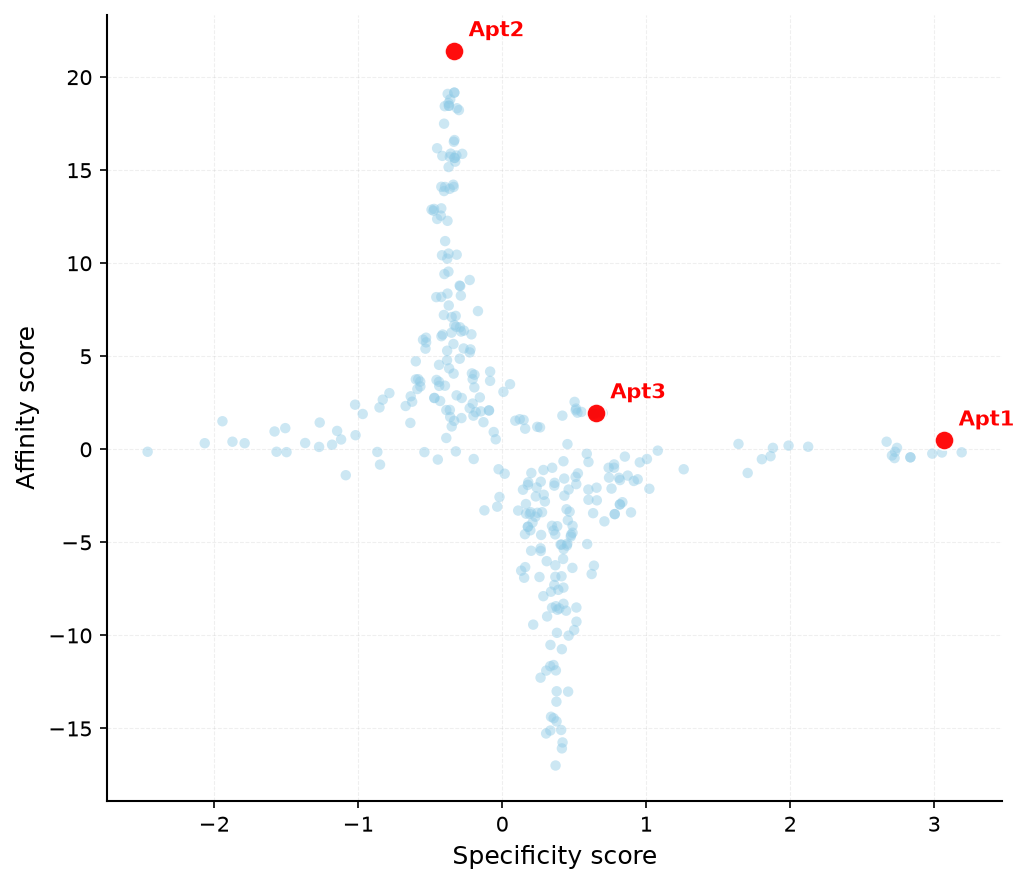

In [19]:
fig, ax = plt.subplots(figsize=(7, 6), dpi=150)

# Selected aptamers
selected = df["aptamer_type"].str.contains("Apt", na=False)

# -------------------------
# All aptamers
# -------------------------
ax.scatter(
    df.loc[~selected, "specificity"],
    df.loc[~selected, "affinity"],
    s=25,
    color="#8ECAE6",
    alpha=0.45,
    edgecolors="none",
    label="Other aptamers"
)

# -------------------------
# Selected aptamers
# -------------------------
ax.scatter(
    df.loc[selected, "specificity"],
    df.loc[selected, "affinity"],
    s=85,
    color="red",
    edgecolors="white",
    linewidth=0.8,
    alpha=0.95,
    zorder=3
)

# -------------------------
# Labels
# -------------------------
for _, row in df.loc[selected].iterrows():
    ax.annotate(
        row["aptamer_type"],
        xy=(row["specificity"], row["affinity"]),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold",
        color="red",
        zorder=4
    )

# -------------------------
# Axes
# -------------------------
ax.set_xlabel("Specificity score", fontsize=12)
ax.set_ylabel("Affinity score", fontsize=12)

ax.tick_params(
    axis="both",
    labelsize=10,
    direction="out"
)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Make remaining borders subtle
ax.spines["left"].set_linewidth(1)
ax.spines["bottom"].set_linewidth(1)

# Very subtle grid
ax.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.2
)

ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "aptamer_affinity_specificity.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>